# 08 — Evaluación temporal final

Evaluamos las 84.233 operaciones futuras del protocolo 07 con LightGBM, su Platt propio y las tres políticas. Conservamos las 432 entradas, los seis Ca hipotéticos y la matriz original. No reajustamos modelos ni usamos estos resultados para modificar las decisiones.

El EDA y el diseño histórico de gaps consultaron estadísticas agregadas de este periodo. Por ello la evaluación es temporal fuera del ajuste de los modelos, pero no un experimento completamente ciego desde el inicio. Los costos son proxies bajo intervención eficaz; no representan ahorros bancarios reales.

## 1. Reproducción entre equipos antes de test

El 07 de nuestro compañero referencia artefactos reconstruidos en Python 3.12, mientras este equipo conserva los originales del 03. También hay tres archivos con diferencias exclusivas de fin de línea. No cambiamos las huellas del protocolo recibido para ocultarlo.

La preparación crea un área local aislada: reutiliza los originales verificados, ejecuta 05/06 y congela 07 allí. Contrasta las doce tablas con atol=rtol=10⁻⁸ y exige las mismas decisiones. Conserva el protocolo inicial y registra una versión local explícita antes de leer etiquetas o puntuar test. Si ya existe la reproducción, solo la verifica.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir() and (p / "notebooks").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from fraud_cost.execution_workspace import prepare_workspace
from fraud_cost.final_evaluation import evaluate_or_load

workspace, protocol, binding = prepare_workspace(ROOT)
print("Versión:", binding["version"], "; doce tablas equivalentes:", binding["tables_equivalent"])
print("Población test congelada:", protocol["test"]["rows"])
display(pd.DataFrame(binding["differences"])[["path", "reason"]])

Reproducción aislada: notebook 5


Reproducción aislada: notebook 6


Reproducción aislada: notebook 7


Doce tablas equivalentes y decisiones iguales; versión local congelada antes de test.


Versión: local_v2 ; doce tablas equivalentes: True
Población test congelada: 84233


,path,reason
0,data/interim/validation_scores.parquet,local_artifact_original_vs_reconstructed
1,results/models/baseline_xgboost_platt.joblib,local_artifact_original_vs_reconstructed
2,results/models/comparacion_modelos_ordinal.joblib,local_artifact_original_vs_reconstructed
3,results/models/lightgbm_seleccionado_platt.joblib,local_artifact_original_vs_reconstructed
4,data/interim/lightgbm_validation_scores.parquet,local_artifact_original_vs_reconstructed
5,src/fraud_cost/data.py,line_endings_only
6,src/fraud_cost/paths.py,line_endings_only
7,src/fraud_cost/__init__.py,line_endings_only


## 2. Ejecución exclusiva y recuperación de resultados

Antes de leer etiquetas se crea un registro exclusivo que identifica la corrida y la versión del protocolo. Comprobamos ID, tiempo y población contra el manifiesto congelado. Calculamos una vez las probabilidades de LightGBM y las seis acciones de los árboles, sin fit.

Si la corrida ya terminó, esta celda verifica y carga sus resultados sin repetir predicciones. Si quedó incompleta, se detiene y conserva el registro para auditarla; no borra el intento ni vuelve a puntuar automáticamente. Los modelos y la validación de la copia principal permanecen intactos.

In [2]:
tables, execution = evaluate_or_load(ROOT)
print("Estado:", execution["status"], "; operaciones:", execution["rows"], "; fraudes:", execution["frauds"])
display(tables["metricas_probabilidades"].round(5))

Test puntuado: 84233 operaciones; 2960 fraudes.


Estado: complete ; operaciones: 84233 ; fraudes: 2960


,probability,rows,frauds,fraud_rate,mean_probability,average_precision,brier_score,log_loss,recall_at_0_5,precision_at_0_5,legitimate_block_rate,block_count,model
0,raw,84233,2960,0.03514,0.03391,0.5178,0.02279,0.09471,0.34966,0.79923,0.0032,1295,lightgbm
1,platt,84233,2960,0.03514,0.03731,0.5178,0.02300,0.09515,0.37264,0.77241,0.0040,1428,lightgbm


## 3. Comparación económica de las tres políticas

Reportamos los seis escenarios y las tres políticas sobre las mismas operaciones. Costo total es intervención más monto fraudulento aprobado. El ahorro frente a la mejor referencia trivial y la mejora frente a fija tienen denominadores distintos. Ca=10 sigue siendo una ilustración fijada previamente, no el valor elegido por este resultado.

TP y FN describen fraudes intervenidos y aprobados; FP y TN, legítimas intervenidas y aprobadas. Las acciones económicas pueden diferir de la clasificación convencional a 0,5. El árbol produce acciones y no se evalúa como si entregara probabilidades calibradas.

,administrative_cost_ca,strategy,cost_total_proxy,administrative_cost_total,missed_fraud_amount,fraud_recall,legitimate_block_rate,amount_weighted_recall,savings_fraction_vs_reference,savings_fraction_vs_fixed_proxy
0,1.0,fixed_0_5,350614.629,1428.0,349186.629,0.37264,0.00400,0.22714,-3.16244,0.00000
1,1.0,bmr,50285.759,32286.0,17999.759,0.86824,0.36563,0.96016,0.40302,0.85658
2,1.0,cost_sensitive_tree,86169.783,32709.0,53460.783,0.81791,0.37267,0.88168,-0.02299,0.75423
3,5.0,fixed_0_5,356326.629,7140.0,349186.629,0.37264,0.00400,0.22714,0.15395,0.00000
4,5.0,bmr,126957.366,63760.0,63197.366,0.67196,0.13243,0.86013,0.69856,0.64371
5,5.0,cost_sensitive_tree,167704.701,65415.0,102289.701,0.59257,0.13939,0.77360,0.60181,0.52935
6,10.0,fixed_0_5,363466.629,14280.0,349186.629,0.37264,0.00400,0.22714,0.19554,0.00000
7,10.0,bmr,181140.258,80810.0,100330.258,0.55845,0.07909,0.77794,0.59908,0.50163
8,10.0,cost_sensitive_tree,228707.974,72120.0,156587.974,0.42432,0.07328,0.65342,0.49380,0.37076
9,20.0,fixed_0_5,377746.629,28560.0,349186.629,0.37264,0.00400,0.22714,0.16393,0.00000


,strategy,TP,FP,FN,TN,precision
6,fixed_0_5,1103,325,1857,80948,0.77241
7,bmr,1653,6428,1307,74845,0.20455
8,cost_sensitive_tree,1256,5956,1704,75317,0.17415


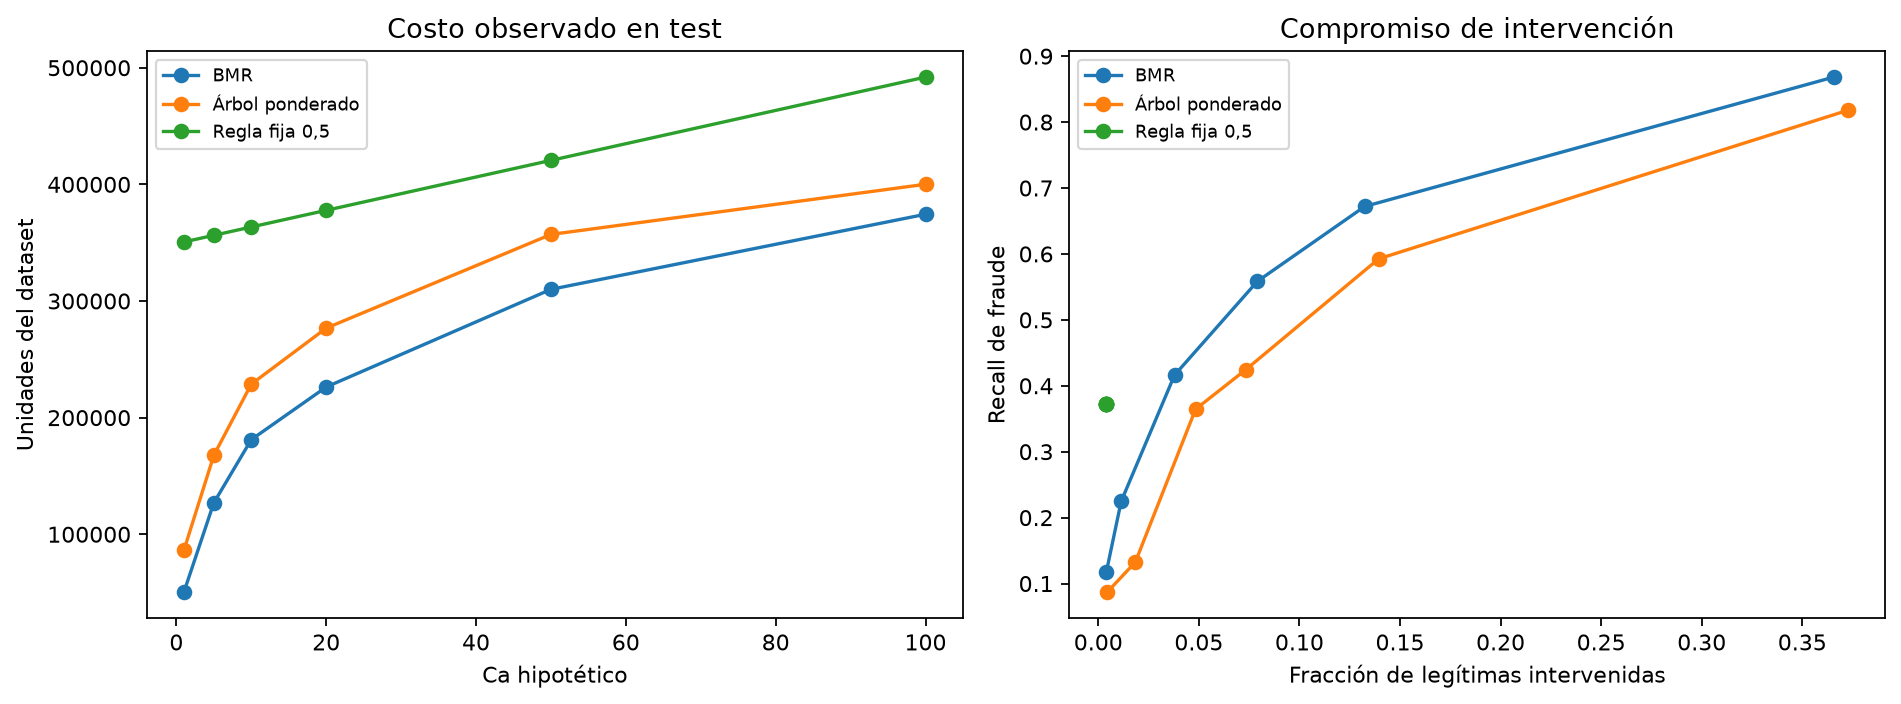

In [3]:
costs = tables["costos"]
display(costs[["administrative_cost_ca", "strategy", "cost_total_proxy", "administrative_cost_total",
    "missed_fraud_amount", "fraud_recall", "legitimate_block_rate", "amount_weighted_recall",
    "savings_fraction_vs_reference", "savings_fraction_vs_fixed_proxy"]].round(5))
display(costs.loc[costs.administrative_cost_ca.eq(10), ["strategy", "TP", "FP", "FN", "TN", "precision"]].round(5))
display(Image(filename=str(ROOT / "results/figures/test_costos_y_operacion.png")))

## 4. Estabilidad y calidad probabilística en el periodo final

Conservamos tres subperiodos de igual duración y las seis bandas de monto del protocolo. No entrenamos dentro de estos grupos. Las medias probabilísticas, AP y costo por operación pueden variar por composición; no atribuimos causalidad ni significación estadística a las diferencias.

Sumamos componentes de costo para comprobar el total, pero no sumamos porcentajes ni referencias mínimas entre subperiodos. Comparamos la exposición esperada con el monto fraudulento observado sin asumir una moneda o pérdida neta real.

,period,boundary_start,boundary_end,end_inclusive,time_start,time_end,rows,frauds,fraud_rate,fraud_amount
0,1,1.327099e+07,1.411771e+07,False,13270993,14117679,29490,911,0.03089,133736.908
1,2,1.411771e+07,1.496442e+07,False,14117884,14964332,29281,990,0.03381,136508.799
2,3,1.496442e+07,1.581113e+07,True,14964456,15811131,25462,1059,0.04159,181567.474


,period,probability,average_precision,brier_score,log_loss,recall_at_0_5,precision_at_0_5,legitimate_block_rate,mean_probability
0,1,raw,0.53865,0.01965,0.08284,0.37761,0.77130,0.00357,0.03200
1,1,platt,0.53865,0.01996,0.08359,0.39737,0.73878,0.00448,0.03498
2,2,raw,0.42630,0.02454,0.10275,0.28283,0.78212,0.00276,0.03421
3,2,platt,0.42630,0.02493,0.10372,0.30505,0.75312,0.00350,0.03804
4,3,raw,0.59202,0.02439,0.09923,0.38810,0.83707,0.00328,0.03578
5,3,platt,0.59202,0.02429,0.09869,0.41454,0.81750,0.00402,0.03919


,amount_band,rows,frauds,observed_rate,mean_raw,mean_platt,observed_fraud_amount,expected_fraud_amount_raw,expected_fraud_amount_platt
0,"[0.0, 50.0)",27001,1159,0.04292,0.03985,0.04315,30958.690,27676.07777,30039.19201
1,"[50.0, 100.0)",22771,640,0.02811,0.02547,0.02797,43989.808,40466.15622,44445.77642
2,"[100.0, 250.0)",25412,690,0.02715,0.03195,0.03568,98542.887,115767.90015,129298.61476
3,"[250.0, 500.0)",5469,258,0.04717,0.04338,0.04801,87859.886,79407.59172,88006.10785
4,"[500.0, 1000.0)",2332,172,0.07376,0.05144,0.05842,128656.950,82317.65684,93714.35090
5,"[1000.0, inf)",1248,41,0.03285,0.02525,0.02869,61804.960,50266.48415,56971.86748


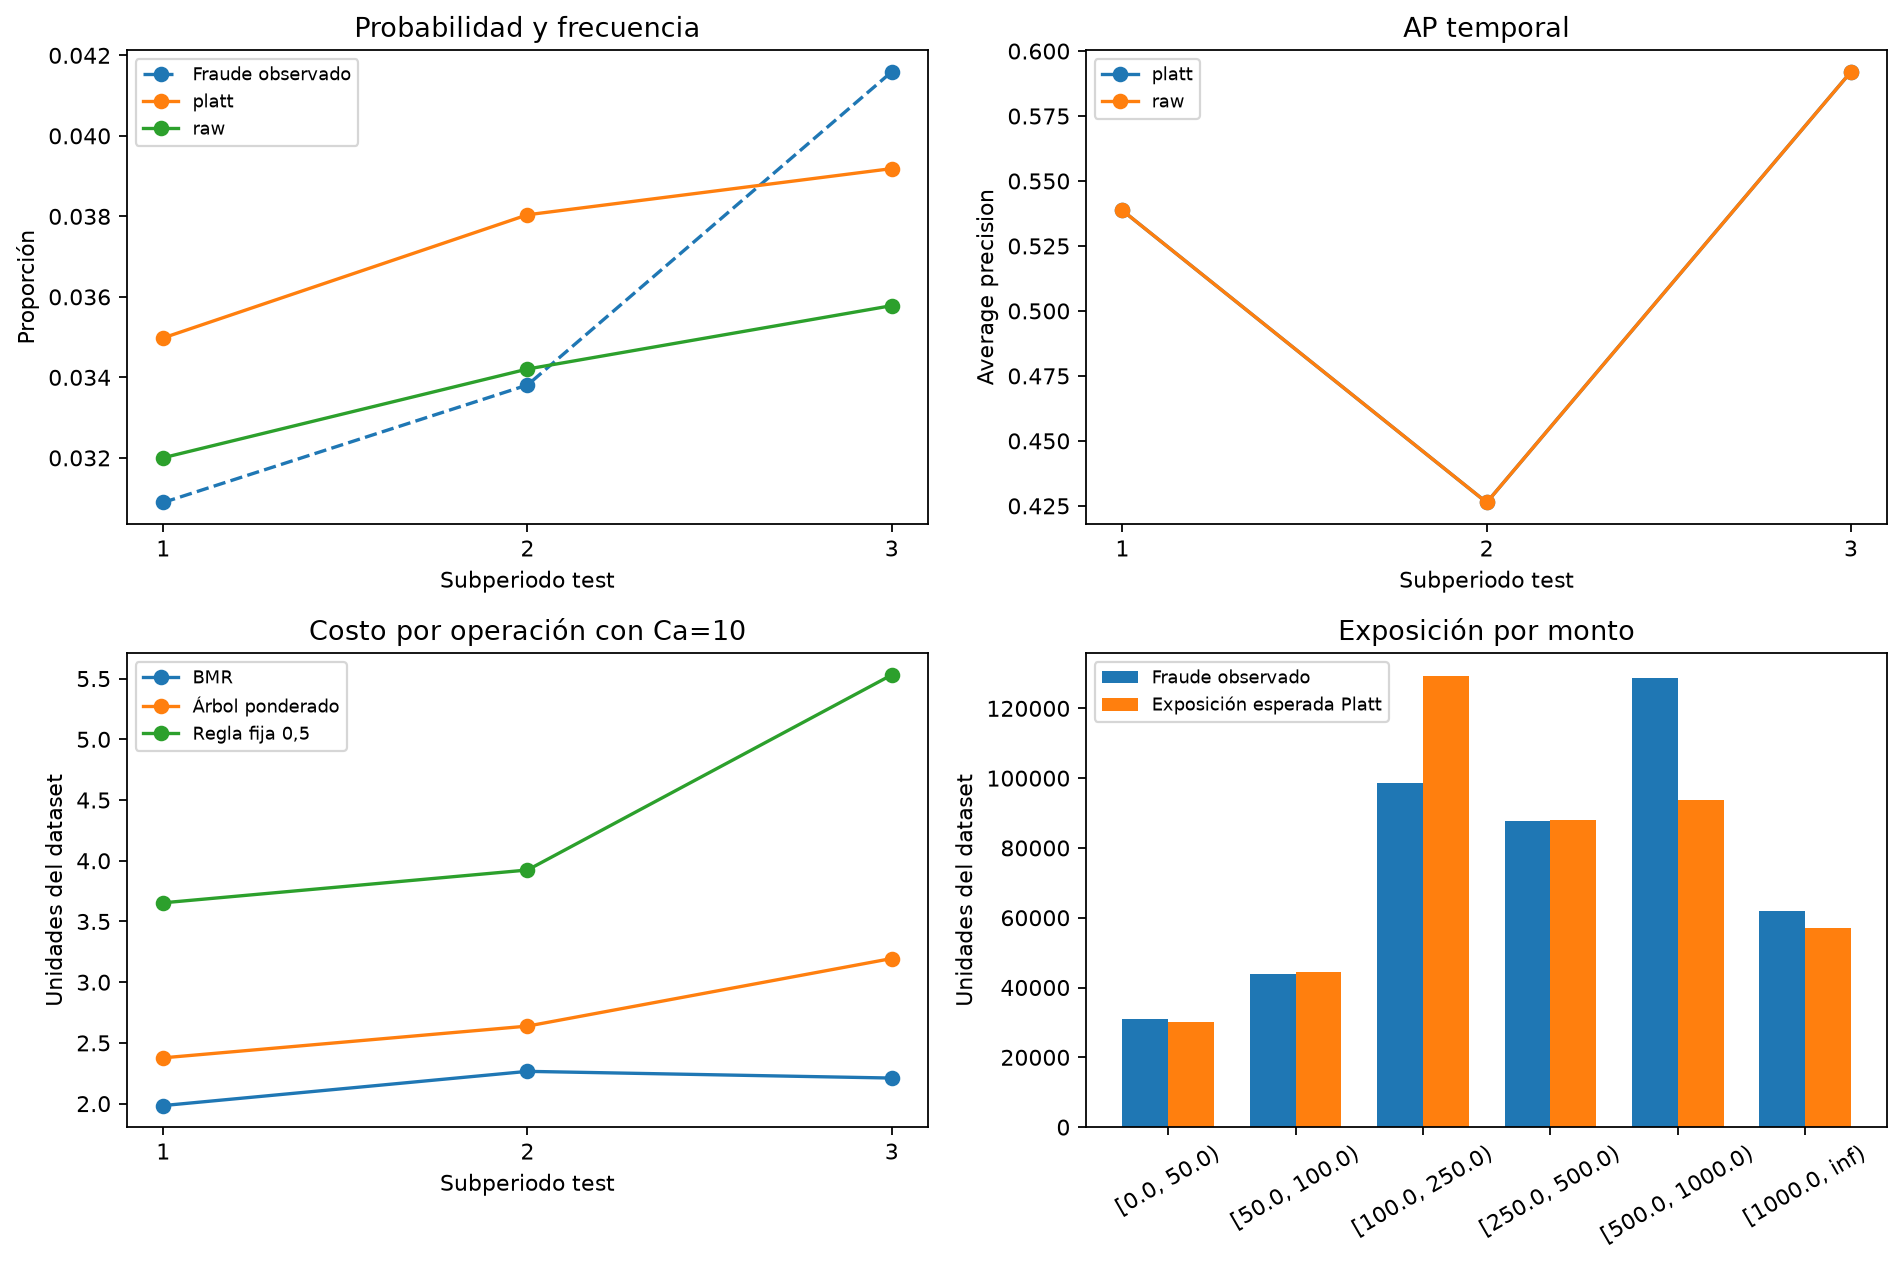

In [4]:
display(tables["periodos"].round(5))
display(tables["metricas_periodo"][["period", "probability", "average_precision", "brier_score", "log_loss",
    "recall_at_0_5", "precision_at_0_5", "legitimate_block_rate", "mean_probability"]].round(5))
display(tables["calibracion_montos"].round(5))
display(Image(filename=str(ROOT / "results/figures/test_estabilidad_y_calibracion.png")))

## 5. Cierre de la evaluación

La ejecución guarda siete tablas agregadas, dos figuras y un registro final; probabilidades y acciones por operación permanecen locales e ignoradas por Git. El protocolo 07 original y su congelación local siguen siendo estados previos a test; el registro 08 acredita que ya se evaluó.

Conservamos modelo, calibración, representación, políticas y Ca después de observar los resultados. Un cambio posterior exige otro experimento y no puede usar este mismo periodo como nueva prueba independiente. El informe 08 sintetiza hallazgos, diferencias con validación y limitaciones para el informe académico final.

## 6. Hallazgos de esta ejecución

Evaluamos **84.233 operaciones y 2.960 fraudes**. LightGBM conserva AP **0,51781** con raw y Platt. En test, Platt empeora ligeramente Brier (**0,02279 → 0,02300**) y log-loss (**0,09471 → 0,09515**); no repetimos la selección del calibrador con esta información.

BMR obtiene menor costo en los seis Ca completos y las 18 combinaciones periodo/Ca. Con **Ca=10**, cuesta **181.140,258**, frente a **363.466,629** de fija y **228.707,974** del árbol. Mejora **50,16%** frente a fija y ahorra **59,91%** frente a la mejor referencia trivial.

Interviene 8.081 operaciones: 1.653 fraudes y 6.428 legítimas. Su recall es **55,84%**, bloqueo de legítimas **7,91%** y captura por monto **77,79%**. Las intervenciones adicionales y sus consecuencias forman parte del compromiso económico.

El comportamiento varía entre periodos y montos. Se mantiene subestimación en [500,1000), aunque la exposición global estimada queda aproximadamente 2,07% por debajo del fraude observado. Las medias globales no garantizan calibración por grupo.

La versión local fue verificada y congelada antes de puntuar; preservamos el protocolo del compañero y la evidencia principal 01–07. El registro acredita una corrida final completa, sin ajustes posteriores. El informe 08 contiene el cierre técnico y sus limitaciones; sigue la síntesis para informe IEEE y sustentación.